In [1]:
%gui asyncio

In [2]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

from clustering.utils import SpaceTimeSVD

from tqdm import tqdm

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 22.3.6


In [3]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [4]:
import tifffile

In [5]:
movie_raw = tifffile.imread("/home/kushal/lab/datasets/jason/M19/D05/M19D5_MC.tif")[:10_000].astype(np.float32)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
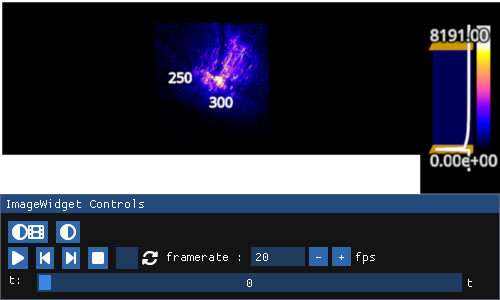

In [6]:
iw_raw = fpl.ImageWidget(movie_raw, cmap="gnuplot2")
iw_raw.show()

In [7]:
movie = movie_raw - movie_raw.mean(axis=0)

In [8]:
movie.shape

(10000, 512, 512)

In [9]:
%matplotlib inline

In [10]:
iw = fpl.ImageWidget(movie.std(axis=0), cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
rs = iw.managed_graphics[0].add_rectangle_selector()
iw.show()

In [11]:
rs.selection = (162, 268, 178, 288)

RFBOutputContext()

JupyterWgpuCanvas()
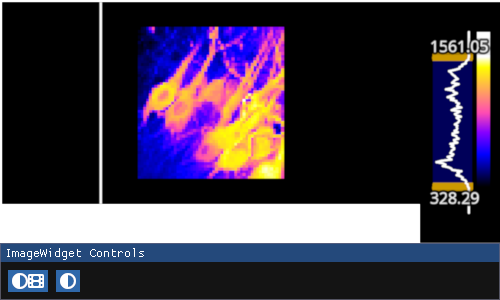

In [12]:
rows, cols = rs.get_selected_indices()
sub = movie[:, rows[0]:rows[-1]:2, cols[0]:cols[-1]:2]
iw_movie = fpl.ImageWidget(sub.std(axis=0), cmap="gnuplot2")
iw_movie.show()

In [13]:
from ipywidgets import IntSlider, VBox

In [14]:
series = sub.reshape(sub.shape[0], sub.shape[1] * sub.shape[2]).T
series.shape

(2915, 10000)

In [15]:
from ipywidgets import HBox

In [16]:
iw_sub = fpl.ImageWidget(sub_raw, cmap="viridis")
# iw_sub.managed_graphics[0].vmin, iw_sub.managed_graphics[0].vmax = (-4000, 4000)
fig = fpl.Figure()

fig[0, 0].add_line(sub_raw[:, 31, 12])

median = fig[0, 0].add_line(np.column_stack([np.arange(sub_raw.shape[0]), np.repeat(np.median(sub_raw[:, 31, 12]), sub_raw.shape[0])]), colors="r")
perc10 = fig[0, 0].add_line(np.column_stack([np.arange(sub_raw.shape[0]), np.repeat(np.percentile(sub_raw[:, 31, 12], 10), sub_raw.shape[0])]), colors="cyan")
perc5 = fig[0, 0].add_line(np.column_stack([np.arange(sub_raw.shape[0]), np.repeat(np.percentile(sub_raw[:, 31, 12], 5), sub_raw.shape[0])]), colors="green")

@iw_sub.managed_graphics[0].add_event_handler("click")
def update_line(ev):
    col, row = ev.pick_info["index"]
    fig[0, 0].graphics[0].data[:, 1] = sub_raw[:, row, col]

    median.data[:, :-1] = np.column_stack([np.arange(sub_raw.shape[0]), np.repeat(np.median(sub_raw[:, row, col]), sub_raw.shape[0])])
    perc10.data[:, :-1] = np.column_stack([np.arange(sub_raw.shape[0]), np.repeat(np.percentile(sub_raw[:, row, col], 10), sub_raw.shape[0])])
    perc5.data[:, :-1] = np.column_stack([np.arange(sub_raw.shape[0]), np.repeat(np.percentile(sub_raw[:, row, col], 5), sub_raw.shape[0])])
    
HBox([iw_sub.show(), fig.show()])

NameError: name 'sub_raw' is not defined

In [16]:
from numba import guvectorize, float64, int64, float32

In [295]:
@guvectorize([(float32[:], float32[:])], "(n)->(n)")
def rolling_percentile(trace: np.ndarray, out: np.ndarray):
    for i in range(0, trace.size - 1):
        out[i] = np.percentile(trace[i:i + 30], 5)

In [321]:
sub_raw = movie_raw[:, rows[0]:rows[-1], cols[0]:cols[-1]]

In [322]:
sub_p10 = np.zeros(sub_raw.shape, dtype=np.float32)

In [324]:
from numba import njit, prange

In [325]:
@njit(parallel=True)
def rolling_percentile_movie(m, output):
    t, row, col = m.shape
    for i in prange(row):
        for j in prange(col):
            rolling_percentile(m[:, i, j], output[:, i, j])

In [326]:
rolling_percentile_movie(sub_raw, sub_p10)

In [ ]:
t, row, col = m.shape
for i in tqdm(range(row)):
    for j in range(col):
        rolling_percentile(m[:, i, j], output[:, i, j])

In [329]:
iw_sub_p10 = fpl.ImageWidget([sub_raw, sub_p10], cmap="viridis", figure_kwargs={"canvas": "glfw"})
iw_sub_p10.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [112]:
iw_sub_p10.figure.canvas.snapshot()

AttributeError: 'GlfwWgpuCanvas' object has no attribute 'snapshot'

In [24]:
figl = fpl.Figure()
figl[0, 0].add_line(trace)
figl[0, 0].add_line(out, colors="r")
figl.show()

RFBOutputContext()

NameError: name 'trace' is not defined

In [330]:
subset = sub_p10

In [331]:
series = subset.reshape(subset.shape[0], subset.shape[1] * subset.shape[2]).T.copy()

In [332]:
series.shape

(11445, 10000)

In [333]:
from sklearn.metrics import pairwise_distances

In [334]:
B = pairwise_distances(series, series, n_jobs=14, metric="cosine")

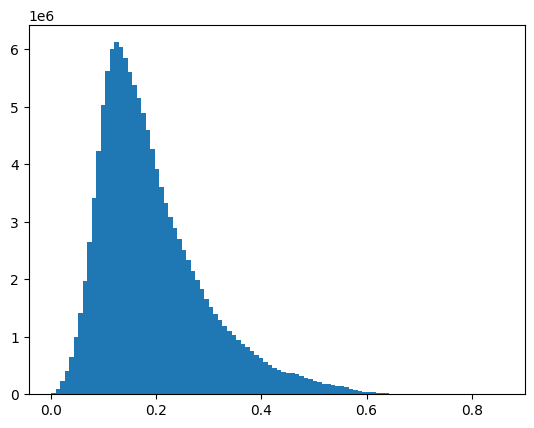

In [335]:
plt.hist(B.ravel(), bins=100)
plt.show()

In [ ]:
d = 1.0 / np.sum(B.astype(np.float64), axis=0)
a = np.diag(d) @ B

In [307]:
a.sum(axis=1)

array([1.        , 1.        , 1.        , ..., 1.        , 0.99999999,
       1.        ])

In [308]:
import pygpcca as gp

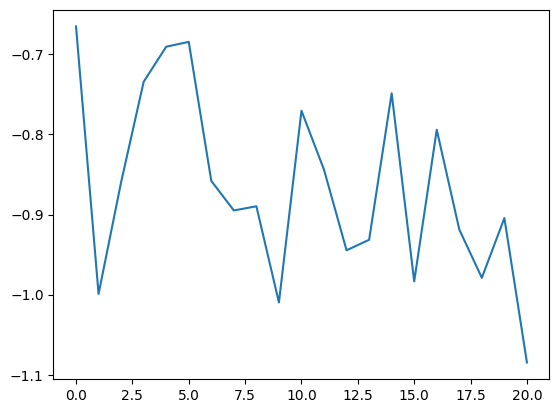

In [309]:
gpcca = gp.GPCCA(a, z="LM", method="brandts")

mc = gpcca.minChi(10, 30)

plt.plot(mc)

In [310]:
mc

[np.float64(-0.6653000141827387),
 np.float64(-0.9990917409885771),
 np.float64(-0.8596163913233755),
 np.float64(-0.7343462805547866),
 np.float64(-0.6905715676697486),
 np.float64(-0.6845124962429295),
 np.float64(-0.85806620209003),
 np.float64(-0.8949325653332761),
 np.float64(-0.8897114018440313),
 np.float64(-1.0097910949673103),
 np.float64(-0.7704332677816059),
 np.float64(-0.844159781050935),
 np.float64(-0.9446619237194448),
 np.float64(-0.9315467029725228),
 np.float64(-0.7486989692352094),
 np.float64(-0.9834711130346507),
 np.float64(-0.7941659610435459),
 np.float64(-0.9187265535633434),
 np.float64(-0.9789881341455369),
 np.float64(-0.9044592373062764),
 np.float64(-1.0846858207045675)]

In [311]:
np.argmax(mc)

np.int64(0)

In [312]:
%%time
gpcca.optimize({'m_min': 15, 'm_max':16})

CPU times: user 24.2 s, sys: 24.8 ms, total: 24.3 s
Wall time: 24.3 s


GPCCA[n=2915, n_macrostates=15]

In [313]:
labels = gpcca.memberships.reshape(sub.shape[1], sub.shape[2], gpcca.memberships.shape[-1])

In [314]:
labels.shape

(55, 53, 15)

In [315]:
fig_comps = fpl.Figure(canvas="glfw")

ix = 0
for i in range(7):
    for j in range(3):
        if ix > labels.shape[-1] - 1:
            break
        img = labels.T[ix].T
        fig_comps[0, 0].add_image(img, cmap="viridis", offset=(i * img.shape[1] + 10 * i, j * img.shape[0] + 10 * j, 0))
        ix += 1

# iw_movie = fpl.ImageWidget(sub, figure_kwargs={"canvas": "glfw"}, cmap="gnuplot2")


fig_comps.show()#, iw_movie.show()